# Scoring System Validation

Validates the domain-expert afternoon tier labels against real covers data.

**Method:**
1. Load scoring system labels from `training_data.csv` (afternoon shift only)
2. Load real covers from `covers_data.csv`
3. Derive ground-truth tiers from covers using tertile bucketing
4. Compare — agreement rate, confusion matrix, breakdown by season/month

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix, classification_report
from pathlib import Path

sns.set_theme(style="whitegrid", palette="muted", font_scale=1.05)
FIG_DIR = Path("../thesis/figures")
FIG_DIR.mkdir(parents=True, exist_ok=True)

## 1. Load data

In [2]:
# Scoring system labels — afternoon only
training = pd.read_csv("../data/prerocessed/training_data.csv", parse_dates=["date"])
afternoon = training[training["shift"] == "afternoon"][["date", "tier", "season", "day_name", "special_day_name"]].copy()
afternoon = afternoon.rename(columns={"tier": "scoring_tier"})

# Real covers
covers = pd.read_csv("../data/raw/covers_data.csv", parse_dates=["date"])
covers = covers[covers["afternoon_covers"].notna() & (covers["afternoon_covers"] != "")].copy()
covers["afternoon_covers"] = pd.to_numeric(covers["afternoon_covers"])

print(f"Scoring system: {len(afternoon)} afternoon days")
print(f"Covers data:    {len(covers)} days with real data")

Scoring system: 840 afternoon days
Covers data:    294 days with real data


## 2. Derive ground-truth tiers from covers

Tertile bucketing: bottom 33% → low, middle → medium, top 33% → high.

In [3]:
low_thresh  = covers["afternoon_covers"].quantile(0.33)
high_thresh = covers["afternoon_covers"].quantile(0.67)

print(f"Tier thresholds from real covers:")
print(f"  low  : covers ≤ {low_thresh:.0f}")
print(f"  medium: {low_thresh:.0f} < covers ≤ {high_thresh:.0f}")
print(f"  high : covers > {high_thresh:.0f}")

def covers_to_tier(c):
    if c <= low_thresh:
        return "low"
    elif c <= high_thresh:
        return "medium"
    else:
        return "high"

covers["covers_tier"] = covers["afternoon_covers"].apply(covers_to_tier)
print(f"\nCovers tier distribution:")
print(covers["covers_tier"].value_counts().sort_index())

Tier thresholds from real covers:
  low  : covers ≤ 182
  medium: 182 < covers ≤ 305
  high : covers > 305

Covers tier distribution:
covers_tier
high       96
low        97
medium    101
Name: count, dtype: int64


## 3. Merge and compare

In [4]:
df = afternoon.merge(covers[["date", "afternoon_covers", "covers_tier"]], on="date", how="inner")
print(f"Overlapping days for validation: {len(df)}")

agreement = (df["scoring_tier"] == df["covers_tier"]).mean()
print(f"\nOverall agreement: {agreement:.1%}")

df.head(10)

Overlapping days for validation: 287

Overall agreement: 50.5%


,date,scoring_tier,season,day_name,special_day_name,afternoon_covers,covers_tier
0,2025-01-10,low,Winter,Friday,NaN,124.0,low
1,2025-01-22,low,Winter,Wednesday,NaN,117.0,low
2,2025-03-03,medium,Spring,Monday,NaN,179.0,low
3,2025-03-27,medium,Spring,Thursday,NaN,308.0,high
4,2025-04-27,low,Spring,Sunday,NaN,149.0,low
5,2025-04-28,medium,Spring,Monday,NaN,182.0,medium
6,2025-04-29,medium,Spring,Tuesday,NaN,161.0,low
7,2025-04-30,medium,Spring,Wednesday,NaN,231.0,medium
8,2025-05-01,high,Spring,Thursday,labour_day,172.0,low
9,2025-05-02,high,Spring,Friday,NaN,205.0,medium


## 4. Confusion matrix

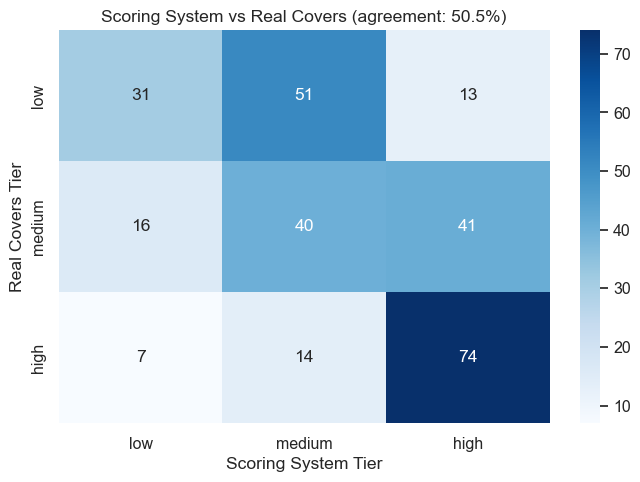

              precision    recall  f1-score   support

         low       0.57      0.33      0.42        95
      medium       0.38      0.41      0.40        97
        high       0.58      0.78      0.66        95

    accuracy                           0.51       287
   macro avg       0.51      0.51      0.49       287
weighted avg       0.51      0.51      0.49       287



In [5]:
labels = ["low", "medium", "high"]
cm = confusion_matrix(df["covers_tier"], df["scoring_tier"], labels=labels)

fig, ax = plt.subplots(figsize=(7, 5))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", ax=ax,
            xticklabels=labels, yticklabels=labels)
ax.set_xlabel("Scoring System Tier")
ax.set_ylabel("Real Covers Tier")
ax.set_title(f"Scoring System vs Real Covers (agreement: {agreement:.1%})")
plt.tight_layout()
fig.savefig(FIG_DIR / "validation_confusion_matrix.png", dpi=150)
plt.show()

print(classification_report(df["covers_tier"], df["scoring_tier"], labels=labels))

## 5. Agreement by season

Agreement by season:
        agreement  n_days
season                   
Autumn      0.337      83
Spring      0.386      44
Summer      0.655      84
Winter      0.592      76


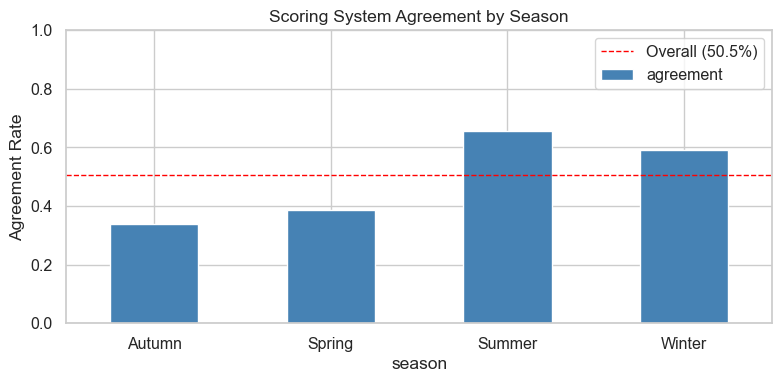

In [6]:
df["correct"] = df["scoring_tier"] == df["covers_tier"]

by_season = df.groupby("season")["correct"].agg(["mean", "count"]).rename(
    columns={"mean": "agreement", "count": "n_days"}
).round(3)

print("Agreement by season:")
print(by_season)

fig, ax = plt.subplots(figsize=(8, 4))
by_season["agreement"].plot(kind="bar", ax=ax, color="steelblue", edgecolor="white")
ax.axhline(agreement, color="red", ls="--", lw=1, label=f"Overall ({agreement:.1%})")
ax.set_ylim(0, 1)
ax.set_ylabel("Agreement Rate")
ax.set_title("Scoring System Agreement by Season")
ax.legend()
plt.xticks(rotation=0)
plt.tight_layout()
fig.savefig(FIG_DIR / "validation_by_season.png", dpi=150)
plt.show()

## 6. Agreement by month

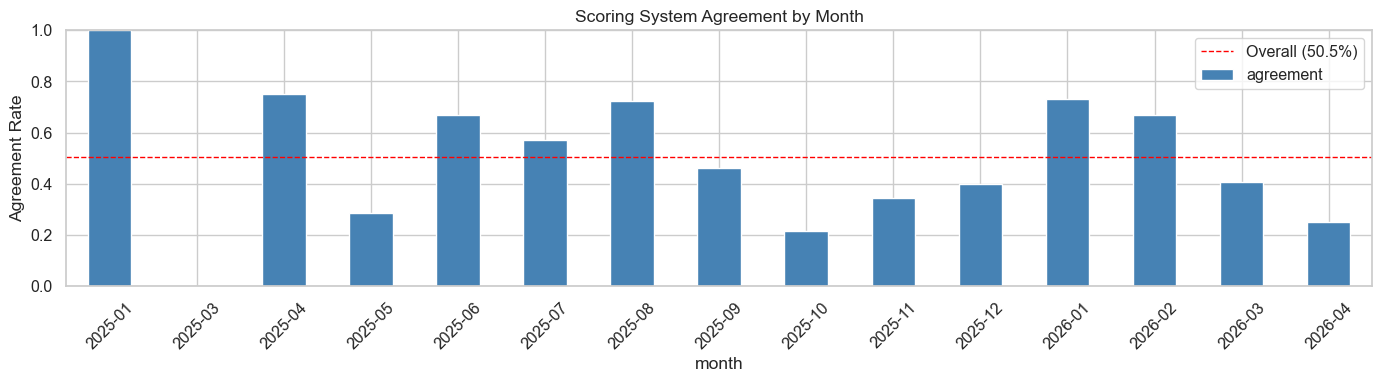

         agreement  n_days
month                     
2025-01      1.000       2
2025-03      0.000       2
2025-04      0.750       4
2025-05      0.286       7
2025-06      0.667      27
2025-07      0.571      28
2025-08      0.724      29
2025-09      0.462      26
2025-10      0.214      28
2025-11      0.345      29
2025-12      0.400      30
2026-01      0.731      26
2026-02      0.667      18
2026-03      0.407      27
2026-04      0.250       4


In [7]:
df["month"] = df["date"].dt.to_period("M").astype(str)

by_month = df.groupby("month")["correct"].agg(["mean", "count"]).rename(
    columns={"mean": "agreement", "count": "n_days"}
).round(3)

fig, ax = plt.subplots(figsize=(14, 4))
by_month["agreement"].plot(kind="bar", ax=ax, color="steelblue", edgecolor="white")
ax.axhline(agreement, color="red", ls="--", lw=1, label=f"Overall ({agreement:.1%})")
ax.set_ylim(0, 1)
ax.set_ylabel("Agreement Rate")
ax.set_title("Scoring System Agreement by Month")
ax.legend()
plt.xticks(rotation=45)
plt.tight_layout()
fig.savefig(FIG_DIR / "validation_by_month.png", dpi=150)
plt.show()

print(by_month)

## 7. Where does the scoring system disagree?

Look at the mismatched days — are there patterns?

In [8]:
mismatches = df[~df["correct"]].sort_values("date")
print(f"{len(mismatches)} mismatched days:")
mismatches[["date", "day_name", "season", "special_day_name", 
            "afternoon_covers", "covers_tier", "scoring_tier"]].to_string(index=False)

142 mismatched days:


'      date  day_name season   special_day_name  afternoon_covers covers_tier scoring_tier\n2025-03-03    Monday Spring                NaN             179.0         low       medium\n2025-03-27  Thursday Spring                NaN             308.0        high       medium\n2025-04-29   Tuesday Spring                NaN             161.0         low       medium\n2025-05-01  Thursday Spring         labour_day             172.0         low         high\n2025-05-02    Friday Spring                NaN             205.0      medium         high\n2025-05-03  Saturday Spring                NaN             286.0      medium         high\n2025-05-05    Monday Spring                NaN             102.0         low       medium\n2025-05-07 Wednesday Spring                NaN              23.0         low       medium\n2025-06-09    Monday Summer        whit_monday             162.0         low         high\n2025-06-10   Tuesday Summer                NaN             213.0      medium         high